# Paper figures from frozen Dataset B artifacts

Reporting-only notebook for paper figures. It performs no fitting, inference, threshold selection, Test re-evaluation, or bootstrap generation. Figure 1 remains unchanged.

## Context & methods

- Code lives only in this notebook.
- Inputs are frozen reporting summaries and accepted RQ4 packages.
- Outputs are written to `reports/paper_figures/` as PDF, SVG, and 300-DPI PNG.
- No figure contains an internal title; panel labels are carried by descriptive subplot titles.
- Figure 2 uses circle/square before-after markers; Figure 3 uses stable circle/square/diamond configuration markers.
- Figure 2 shows the primary randomized-decision seed 42 only and therefore has no seed-variability interval.
- Figure 3 error bars are sample SD across seeds 42/43/44 (`ddof=1`), not confidence intervals or sampling uncertainty.
- RQ4b primary display is limited to six units: seeds 42/43/44 crossed with λ=0/0.01.
- RQ4b ΔDPD3 and ΔDPD6 are deterministic transforms of stored group counts; no unsupported DPD confidence interval is created.

In [1]:
from pathlib import Path
import hashlib
import json
import time
from uuid import uuid4

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display


def find_repo_root():
    for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (candidate / 'artifacts' / 'dataset_b').is_dir() and (candidate / 'notebooks' / 'dataset_b').is_dir():
            return candidate
    raise FileNotFoundError('Could not locate repository root.')


REPO_ROOT = find_repo_root()
OUTPUT_ROOT = REPO_ROOT / 'reports' / 'paper_figures'
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
MODEL_ORDER = ['lr', 'rf', 'xgboost', 'plain_mlp', 'realmlp', 'tabmmini']
MODEL_LABELS = {'lr': 'LR', 'rf': 'RF', 'xgboost': 'XGBoost', 'plain_mlp': 'PlainMLP', 'realmlp': 'RealMLP', 'tabmmini': 'TabMmini'}
FIGURE_WIDTH = 12.0 / 2.54
CHARCOAL, ACCENT = '#30343B', '#4C708B'

mpl.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'font.family': 'DejaVu Sans', 'font.size': 8.5, 'axes.labelsize': 8.5,
    'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8,
    'axes.edgecolor': CHARCOAL, 'axes.linewidth': 0.7, 'axes.grid': True,
    'axes.axisbelow': True, 'grid.color': '#D6D9DD', 'grid.linewidth': 0.55,
    'grid.alpha': 0.75, 'grid.linestyle': ':', 'pdf.fonttype': 42,
    'ps.fonttype': 42, 'svg.fonttype': 'none'
})


def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def polish(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(False)
    ax.grid(True, axis='x')


def save_atomic(fig, output_path, **kwargs):
    output_path = Path(output_path)
    temporary = output_path.with_name(f'.{output_path.stem}.{uuid4().hex}.tmp{output_path.suffix}')
    try:
        fig.savefig(temporary, **kwargs)
        for attempt in range(5):
            try:
                temporary.replace(output_path)
                return
            except OSError:
                if attempt == 4:
                    raise
                time.sleep(0.2 * (attempt + 1))
    finally:
        temporary.unlink(missing_ok=True)


def export_figure(fig, stem):
    paths = []
    for suffix, kwargs in [('.pdf', {}), ('.svg', {}), ('.png', {'dpi': 300})]:
        path = OUTPUT_ROOT / f'{stem}{suffix}'
        save_atomic(fig, path, bbox_inches='tight', pad_inches=0.04, **kwargs)
        paths.append(path)
    plt.close(fig)
    return paths


def interval_errors(frame, point='estimate', low='ci_low', high='ci_high'):
    values = frame[point].to_numpy(float)
    return np.vstack([values - frame[low].to_numpy(float), frame[high].to_numpy(float) - values])

print('Repository:', REPO_ROOT)
print('Output:', OUTPUT_ROOT.relative_to(REPO_ROOT))

Repository: D:\FPTU_Study\FA2026\DAP391m_GR12
Output: reports\paper_figures


## Data and source verification

In [2]:
RQ1_PATHS = {
    'lr': REPO_ROOT / 'artifacts/dataset_b/lr/final/lr_final_15f_20261002_01/reporting/rq1_metrics_long.csv',
    'rf': REPO_ROOT / 'artifacts/dataset_b/rf/final/rf_final_15f_20261002_01/reporting/rq1_metrics_long.csv',
    'xgboost': REPO_ROOT / 'artifacts/dataset_b/xgboost/final/xgb_final_15f_20261003_01/reporting/rq1_metrics_long.csv',
    'plain_mlp': REPO_ROOT / 'artifacts/dataset_b/plain_mlp/final/plain_mlp_final_15f_20261004_03/reporting/rq1_metrics_long.csv',
    'realmlp': REPO_ROOT / 'artifacts/dataset_b/realmlp/final/realmlp_final_15f_20261004_01/reporting/rq1_metrics_long.csv',
    'tabmmini': REPO_ROOT / 'artifacts/dataset_b/tabmmini/final/tabmmini_final_15f_20261004_01/reporting/rq1_metrics_long.csv',
}
RQ3_ROOT = REPO_ROOT / 'artifacts/dataset_b/rq3/rq3_fairness_20261010_01'
RQ4A_ROOTS = {
    'G3': REPO_ROOT / 'artifacts/dataset_b/rq4/rq4a/rq4a3_postproc_20261017_01',
    'G6': REPO_ROOT / 'artifacts/dataset_b/rq4/rq4a/rq4a6_postproc_20261017_01',
}
RQ4A_G3_GROUP_METRICS = RQ4A_ROOTS['G3'] / 'reporting/group_metrics.csv'
RQ4B_ROOT = REPO_ROOT / 'artifacts/dataset_b/rq4/rq4b/test_evaluation/rq4b3_test_20261024_01'
RQ4B_STAGE = RQ4B_ROOT / 'stages/test_evaluation'
RQ4B_PACKAGE = RQ4B_ROOT / 'stages/package_validation'
BOOTSTRAP_INDEX = REPO_ROOT / 'artifacts/dataset_b/rq1_test_bootstrap_indices.npz'

required_paths = [*RQ1_PATHS.values(), RQ3_ROOT / 'status.json', RQ3_ROOT / 'group_metrics.csv', RQ3_ROOT / 'bootstrap_summary.csv',
                  RQ4A_G3_GROUP_METRICS,
                  *(root / 'reporting/model_summary.json' for root in RQ4A_ROOTS.values()),
                  RQ4B_ROOT / 'run_manifest.json', RQ4B_STAGE / 'arm_metrics.csv', RQ4B_STAGE / 'group_metrics.csv',
                  RQ4B_STAGE / 'matched_deltas.csv', RQ4B_STAGE / 'bootstrap_summary.csv', RQ4B_STAGE / 'receipt.json',
                  RQ4B_PACKAGE / 'receipt.json', BOOTSTRAP_INDEX]
missing = [str(path) for path in required_paths if not path.is_file()]
assert not missing, f'Missing required sources: {missing}'

# RQ1 locked Test estimates and per-model bootstrap intervals.
rq1_parts = []
for model, path in RQ1_PATHS.items():
    frame = pd.read_csv(path)
    frame['model'] = model
    rq1_parts.append(frame)
rq1 = pd.concat(rq1_parts, ignore_index=True)
needed_metrics = ['roc_auc_approved', 'f1_denied', 'brier_score_approved']
rq1_plot = rq1[rq1['metric'].isin(needed_metrics)].copy()
assert rq1_plot.groupby(['model', 'metric']).size().eq(1).all()
assert set(rq1_plot['model']) == set(MODEL_ORDER)
assert np.isfinite(rq1_plot[['estimate', 'ci_low', 'ci_high']].to_numpy(float)).all()
assert (rq1_plot['ci_low'] <= rq1_plot['estimate']).all() and (rq1_plot['estimate'] <= rq1_plot['ci_high']).all()

# RQ3 baseline EOD.
rq3_status = json.loads((RQ3_ROOT / 'status.json').read_text(encoding='utf-8'))
assert rq3_status['status'] == 'PASS' and set(rq3_status['model_status'].values()) == {'PASS'}
group_metrics = pd.read_csv(RQ3_ROOT / 'group_metrics.csv')
bootstrap_summary = pd.read_csv(RQ3_ROOT / 'bootstrap_summary.csv')
g3_groups = ['White', 'Black or African American', 'Asian']
eod3_rows = []
for model in MODEL_ORDER:
    subset = group_metrics[(group_metrics['model'] == model) & (group_metrics['attribute'] == 'derived_race') & group_metrics['group'].isin(g3_groups)]
    pivot = subset[subset['metric'].isin(['tpr_approved', 'fpr_approved'])].pivot(index='group', columns='metric', values='value').astype(float)
    assert set(pivot.index) == set(g3_groups) and np.isfinite(pivot.to_numpy()).all()
    eod3_rows.append({'model': model, 'estimate': max(pivot['tpr_approved'].max() - pivot['tpr_approved'].min(), pivot['fpr_approved'].max() - pivot['fpr_approved'].min())})
eod3 = pd.DataFrame(eod3_rows)
eod6 = bootstrap_summary[(bootstrap_summary['attribute'] == 'derived_race') & (bootstrap_summary['result_type'] == 'global_range') & (bootstrap_summary['metric'] == 'equalized_odds_difference_range')].copy()
assert set(eod6['model']) == set(MODEL_ORDER) and eod6['ci_status'].eq('defined').all()
g6_groups = ['White', 'Black or African American', 'Asian', 'American Indian or Alaska Native', '2 or more minority races', 'Joint']
frozen_rows = group_metrics[(group_metrics['model'] == 'realmlp') & (group_metrics['attribute'] == 'derived_race') & group_metrics['group'].isin(g6_groups) & group_metrics['metric'].isin(['tpr_approved', 'fpr_approved'])].copy()
assert len(frozen_rows) == 12 and frozen_rows['status'].eq('defined').all()
frozen_realmlp = frozen_rows.pivot(index='group', columns='metric', values='value').astype(float).loc[g6_groups]
frozen_fpr_denominators = frozen_rows[frozen_rows['metric'] == 'fpr_approved'].set_index('group')['denominator'].astype(int).loc[g6_groups]

# RQ4a accepted refit-bootstrap summaries.
rq4a_records = []
for scope, root in RQ4A_ROOTS.items():
    payload = json.loads((root / 'reporting/model_summary.json').read_text(encoding='utf-8'))
    for model in ['xgboost', 'realmlp']:
        row = payload['model_summaries'][model]
        rq4a_records.append({'model': model, 'scope': scope, 'label': f"{MODEL_LABELS[model]}–{scope}",
                             'delta_eod': row['point_delta_target_eod'], 'delta_eod_low': row['delta_target_eod_ci'][0], 'delta_eod_high': row['delta_target_eod_ci'][1],
                             'ba_cost': row['point_ba_cost'], 'ba_cost_low': row['ba_cost_ci'][0], 'ba_cost_high': row['ba_cost_ci'][1]})
rq4a_order = ['XGBoost–G3', 'RealMLP–G3', 'XGBoost–G6', 'RealMLP–G6']
rq4a = pd.DataFrame(rq4a_records).set_index('label').loc[rq4a_order].reset_index()
for prefix in ['delta_eod', 'ba_cost']:
    assert (rq4a[f'{prefix}_low'] <= rq4a[prefix]).all() and (rq4a[prefix] <= rq4a[f'{prefix}_high']).all()
rq4a_group_metrics = pd.read_csv(RQ4A_G3_GROUP_METRICS, float_precision='round_trip')
post_group_rates = rq4a_group_metrics[(rq4a_group_metrics['partition'] == 'test') & (rq4a_group_metrics['attribute'] == 'derived_race') & rq4a_group_metrics['model'].isin(['xgboost', 'realmlp']) & rq4a_group_metrics['policy'].isin(['baseline', 'mitigated']) & rq4a_group_metrics['group'].isin(g3_groups) & rq4a_group_metrics['in_target_roster'].astype(str).str.lower().eq('true')].copy()
assert len(post_group_rates) == 12
assert post_group_rates.groupby(['model', 'policy']).size().eq(3).all()
assert post_group_rates[['tpr', 'fpr']].apply(np.isfinite).all().all()

# RQ4b is restricted to six units: seeds 42/43/44 × lambda 0/0.01.
rq4b_manifest = json.loads((RQ4B_ROOT / 'run_manifest.json').read_text(encoding='utf-8'))
assert rq4b_manifest['bootstrap_index_pin']['sha256'] == sha256(BOOTSTRAP_INDEX)
arm_metrics = pd.read_csv(RQ4B_STAGE / 'arm_metrics.csv', float_precision='round_trip')
rq4b_groups = pd.read_csv(RQ4B_STAGE / 'group_metrics.csv', float_precision='round_trip')
matched = pd.read_csv(RQ4B_STAGE / 'matched_deltas.csv', float_precision='round_trip')
paired_ci = pd.read_csv(RQ4B_STAGE / 'bootstrap_summary.csv', float_precision='round_trip')
rq4b_group_display = rq4b_groups[(rq4b_groups['roster'] == 'g6') & rq4b_groups['seed'].isin([42, 43, 44]) & (np.isclose(rq4b_groups['adversary_lambda'], 0.0) | np.isclose(rq4b_groups['adversary_lambda'], 0.01)) & rq4b_groups['group'].isin(g6_groups)].copy()
assert len(rq4b_group_display) == 36
assert rq4b_group_display[['tpr_approved', 'fpr_approved']].apply(np.isfinite).all().all()
rq4b_group_summary = rq4b_group_display.groupby(['adversary_lambda', 'group'], as_index=False).agg(seed_count=('seed', 'nunique'), tpr_mean=('tpr_approved', 'mean'), tpr_sd=('tpr_approved', lambda values: values.std(ddof=1)), fpr_mean=('fpr_approved', 'mean'), fpr_sd=('fpr_approved', lambda values: values.std(ddof=1)))
assert len(rq4b_group_summary) == 12 and rq4b_group_summary['seed_count'].eq(3).all()
assert np.isfinite(rq4b_group_summary[['tpr_mean', 'tpr_sd', 'fpr_mean', 'fpr_sd']].to_numpy(float)).all()
unit_order = [(42, 0.0), (42, 0.01), (43, 0.0), (43, 0.01), (44, 0.0), (44, 0.01)]
unit_records = []
for seed, lam in unit_order:
    row = arm_metrics[(arm_metrics['seed'] == seed) & np.isclose(arm_metrics['adversary_lambda'], lam)].iloc[0]
    unit_records.append({'seed': seed, 'lambda': lam, 'label': f'seed {seed}, λ={lam:g}', 'eod3': row['eod3'], 'balanced_accuracy': row['balanced_accuracy']})
rq4b_units = pd.DataFrame(unit_records)
assert len(rq4b_units) == 6 and np.isfinite(rq4b_units[['eod3', 'balanced_accuracy']].to_numpy(float)).all()

# Secondary matched deltas: EOD6 from stored matched output; DPD from stored group counts.
def dpd_from_group_counts(seed, lam, roster):
    subset = rq4b_groups[(rq4b_groups['seed'] == seed) & np.isclose(rq4b_groups['adversary_lambda'], lam) & (rq4b_groups['roster'] == roster)].copy()
    expected = 3 if roster == 'g3' else 6
    assert len(subset) == expected and (subset['row_count'].astype(int) > 0).all()
    rates = subset['predicted_approved_count'].astype(float) / subset['row_count'].astype(float)
    return rates.max() - rates.min()

secondary_records = []
for seed in [42, 43, 44]:
    point = matched[(matched['seed'] == seed) & np.isclose(matched['comparator_lambda'], 0.01)].iloc[0]
    eod6_ci = paired_ci[(paired_ci['seed'] == seed) & np.isclose(paired_ci['comparator_lambda'], 0.01) & (paired_ci['quantity'] == 'delta_eod6')].iloc[0]
    assert int(eod6_ci['valid_replicates']) == 1000 and int(eod6_ci['invalid_replicates']) == 0
    secondary_records.append({
        'seed': seed, 'label': f'seed {seed}', 'delta_eod6': point['delta_eod6'],
        'delta_eod6_low': eod6_ci['lower'], 'delta_eod6_high': eod6_ci['upper'],
        'delta_dpd3': dpd_from_group_counts(seed, 0.01, 'g3') - dpd_from_group_counts(seed, 0.0, 'g3'),
        'delta_dpd6': dpd_from_group_counts(seed, 0.01, 'g6') - dpd_from_group_counts(seed, 0.0, 'g6'),
    })
rq4b_secondary = pd.DataFrame(secondary_records)
assert np.isfinite(rq4b_secondary[['delta_eod6', 'delta_eod6_low', 'delta_eod6_high', 'delta_dpd3', 'delta_dpd6']].to_numpy(float)).all()
assert (rq4b_secondary['delta_eod6_low'] <= rq4b_secondary['delta_eod6']).all() and (rq4b_secondary['delta_eod6'] <= rq4b_secondary['delta_eod6_high']).all()

print('Source verification: PASS')
print('RQ4b units:', rq4b_units['label'].tolist())

Source verification: PASS
RQ4b units: ['seed 42, λ=0', 'seed 42, λ=0.01', 'seed 43, λ=0', 'seed 43, λ=0.01', 'seed 44, λ=0', 'seed 44, λ=0.01']


## Results

### Figure 2 — G3 post-processing changes in group error rates

Test-set TPR/FPR for White, Black or African American, and Asian groups. Circles are frozen-model rates; squares are G3 `ThresholdOptimizer` rates from decision seed 42. Each connector is within one group only. Axes are zoomed and not zero-based; Table 3 remains the source for exact fairness and balanced-accuracy costs.

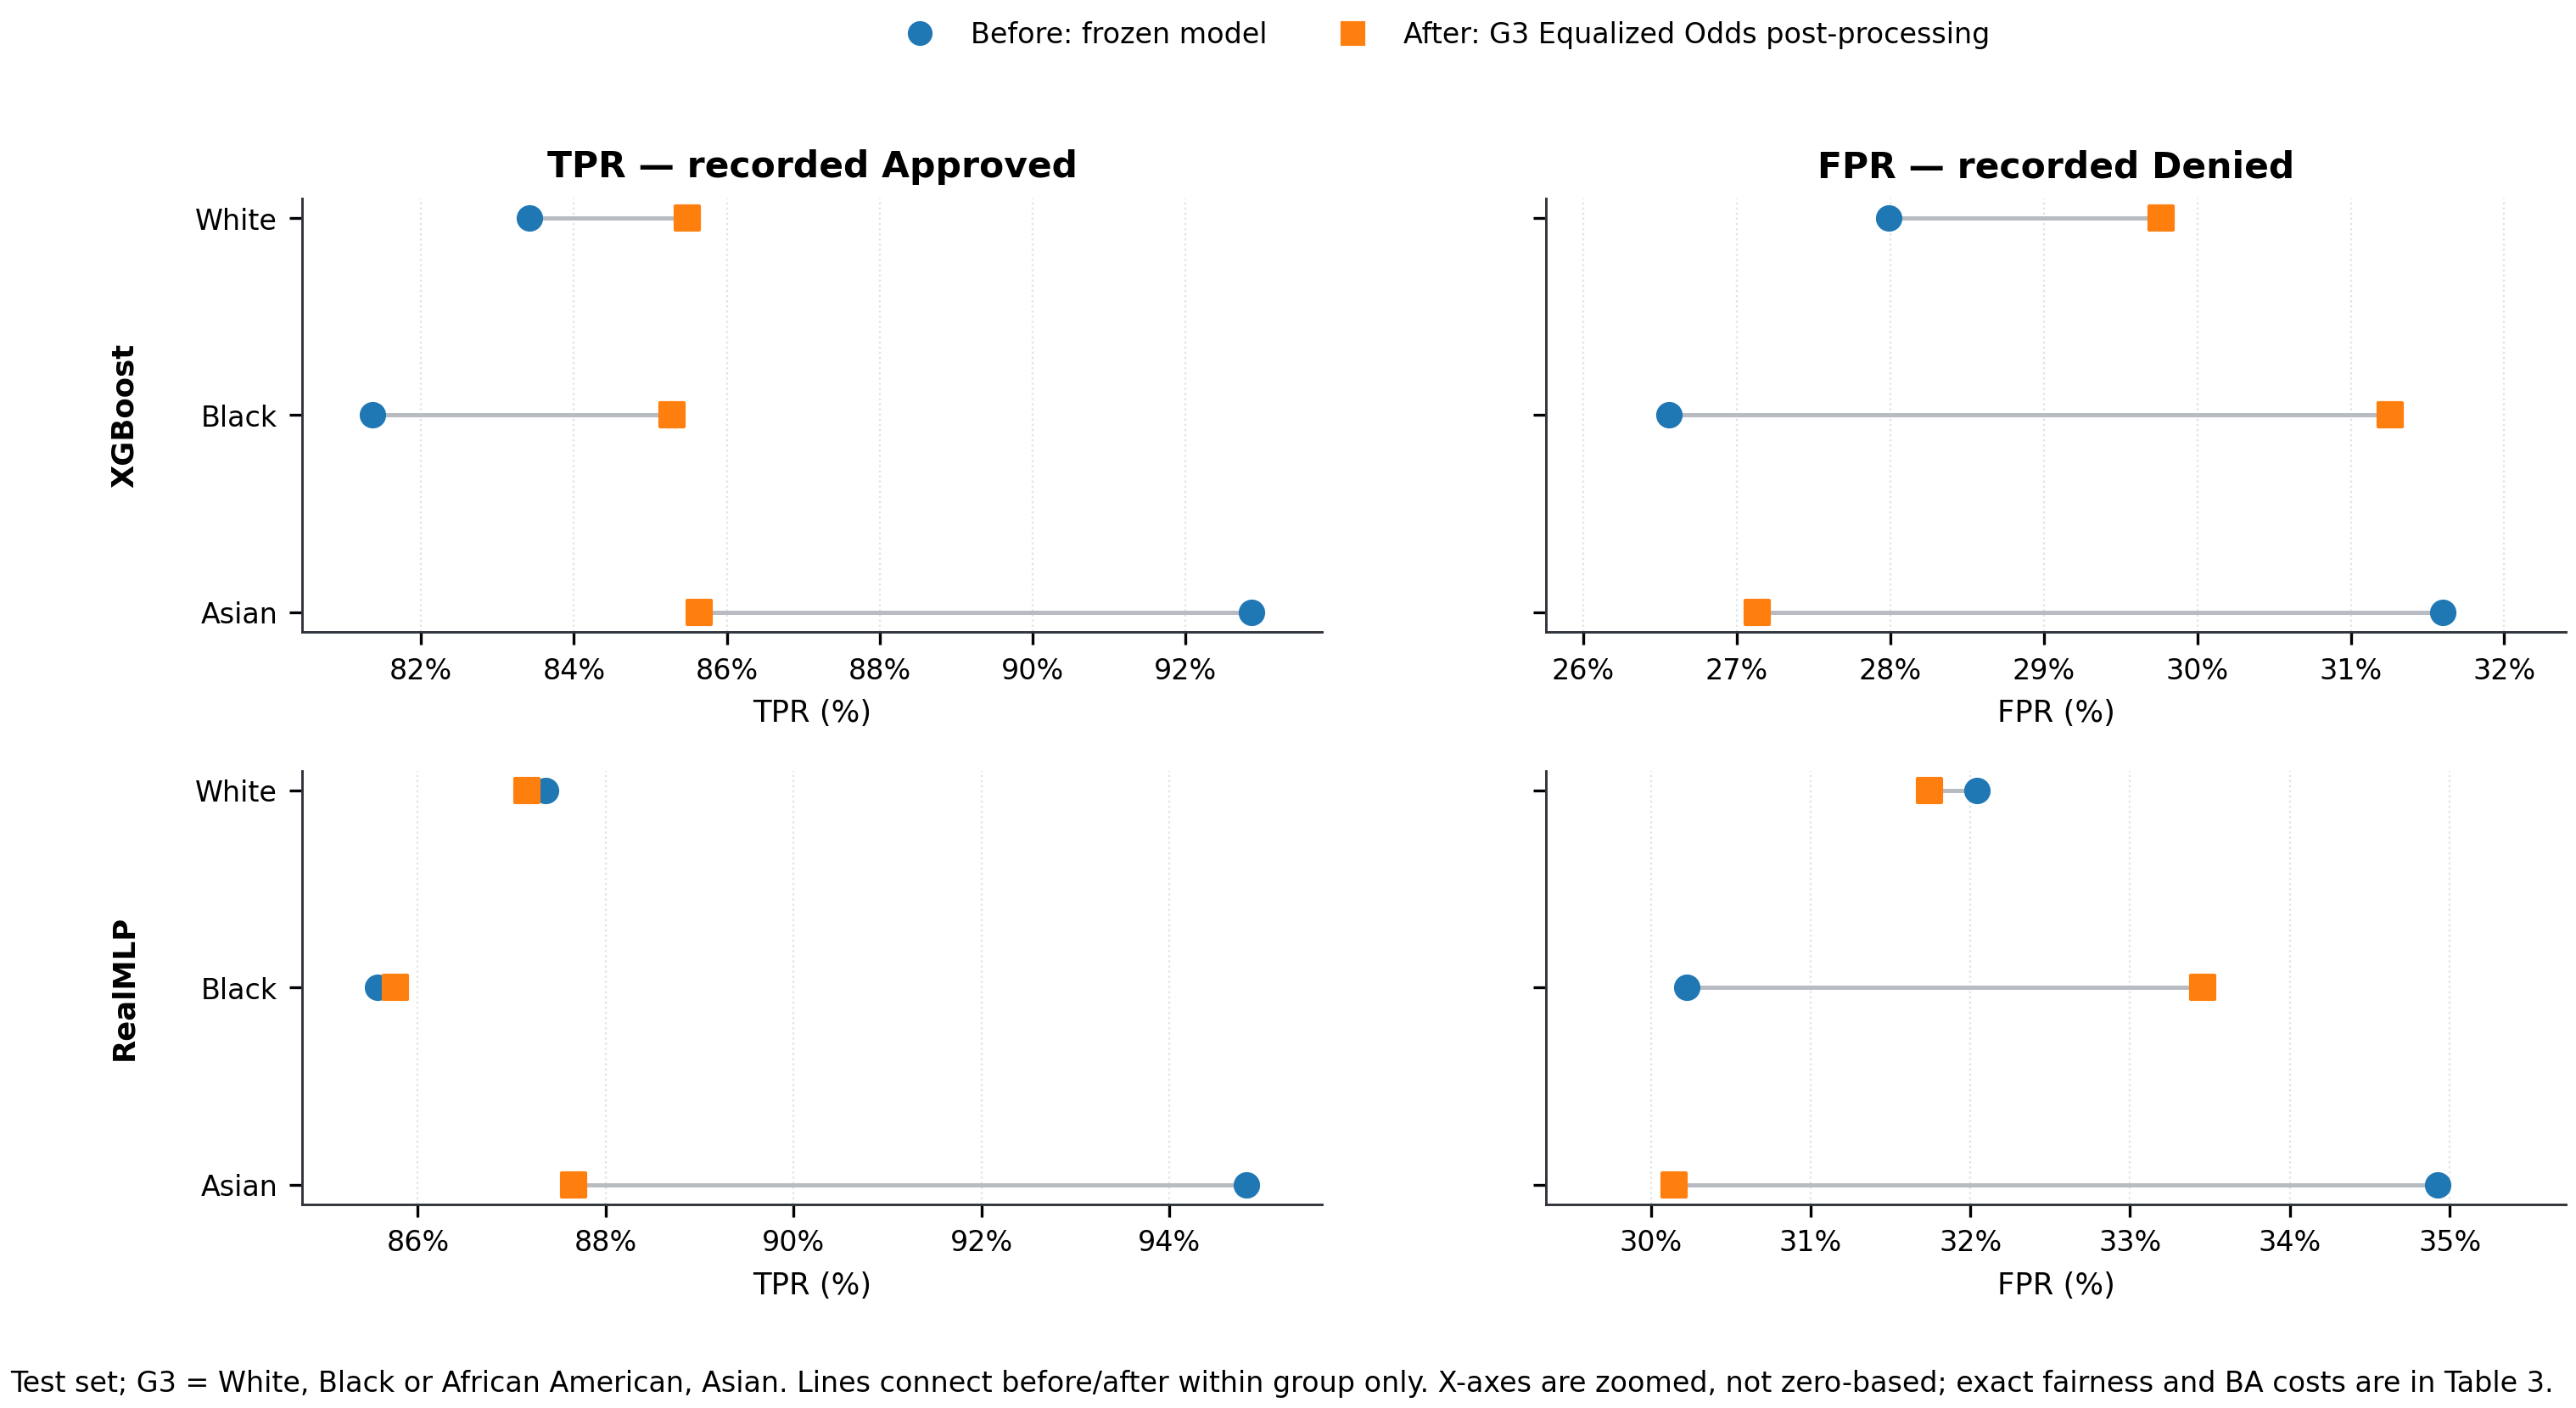

In [9]:
before_color, after_color, connector_color = '#1F77B4', '#FF7F0E', '#B8BCC2'
fig, axes = plt.subplots(2, 2, figsize=(10.4, 5.9), sharey=True)
fig.subplots_adjust(left=0.13, right=0.985, top=0.83, bottom=0.16, hspace=0.32, wspace=0.22)
y = np.arange(len(g3_groups))[::-1]
metric_columns = [('tpr', 'TPR — recorded Approved'), ('fpr', 'FPR — recorded Denied')]
legend_handles = [
    mpl.lines.Line2D([], [], marker='o', linestyle='None', color=before_color, markersize=6, label='Before: frozen model'),
    mpl.lines.Line2D([], [], marker='s', linestyle='None', color=after_color, markersize=6, label='After: G3 Equalized Odds post-processing'),
]
for row_index, model in enumerate(['xgboost', 'realmlp']):
    model_rates = post_group_rates[post_group_rates['model'] == model]
    before = model_rates[model_rates['policy'] == 'baseline'].set_index('group').loc[g3_groups]
    after = model_rates[model_rates['policy'] == 'mitigated'].set_index('group').loc[g3_groups]
    for column_index, (metric, title) in enumerate(metric_columns):
        ax = axes[row_index, column_index]
        before_values = before[metric].to_numpy(float) * 100
        after_values = after[metric].to_numpy(float) * 100
        for group_y, before_value, after_value in zip(y, before_values, after_values):
            ax.plot([before_value, after_value], [group_y, group_y], color=connector_color, linewidth=1.2, zorder=1)
        ax.scatter(before_values, y, color=before_color, marker='o', s=42, zorder=2)
        ax.scatter(after_values, y, color=after_color, marker='s', s=42, zorder=3)
        combined = np.concatenate([before_values, after_values])
        padding = max(0.8, 0.08 * np.ptp(combined))
        ax.set_xlim(combined.min() - padding, combined.max() + padding)
        ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(xmax=100, decimals=0))
        ax.set_xlabel(f'{metric.upper()} (%)')
        if row_index == 0:
            ax.set_title(title, fontweight='bold')
        ax.set_yticks(y, ['White', 'Black', 'Asian'])
        polish(ax)
    axes[row_index, 0].set_ylabel(MODEL_LABELS[model], fontweight='bold', labelpad=16)
fig.legend(handles=legend_handles, loc='upper center', ncol=2, frameon=False, bbox_to_anchor=(0.56, 0.965))
fig.text(0.5, 0.035, 'Test set; G3 = White, Black or African American, Asian. Lines connect before/after within group only. X-axes are zoomed, not zero-based; exact fairness and BA costs are in Table 3.', ha='center', fontsize=8)
fig02_paths = export_figure(fig, 'fig02_postprocessing_group_error_rates')
display(Image(filename=str(fig02_paths[-1]), width=567))

### Figure 3 — Adversarial-training group error rates

Frozen RealMLP is one model and therefore has no error bar. Retrained λ=0 and adversarial λ=0.01 show mean ± sample SD across seeds 42/43/44 (`ddof=1`), not 95% confidence intervals or sampling uncertainty. The dashed separator divides G3 from the three G6-only groups; axes are zoomed and not zero-based.

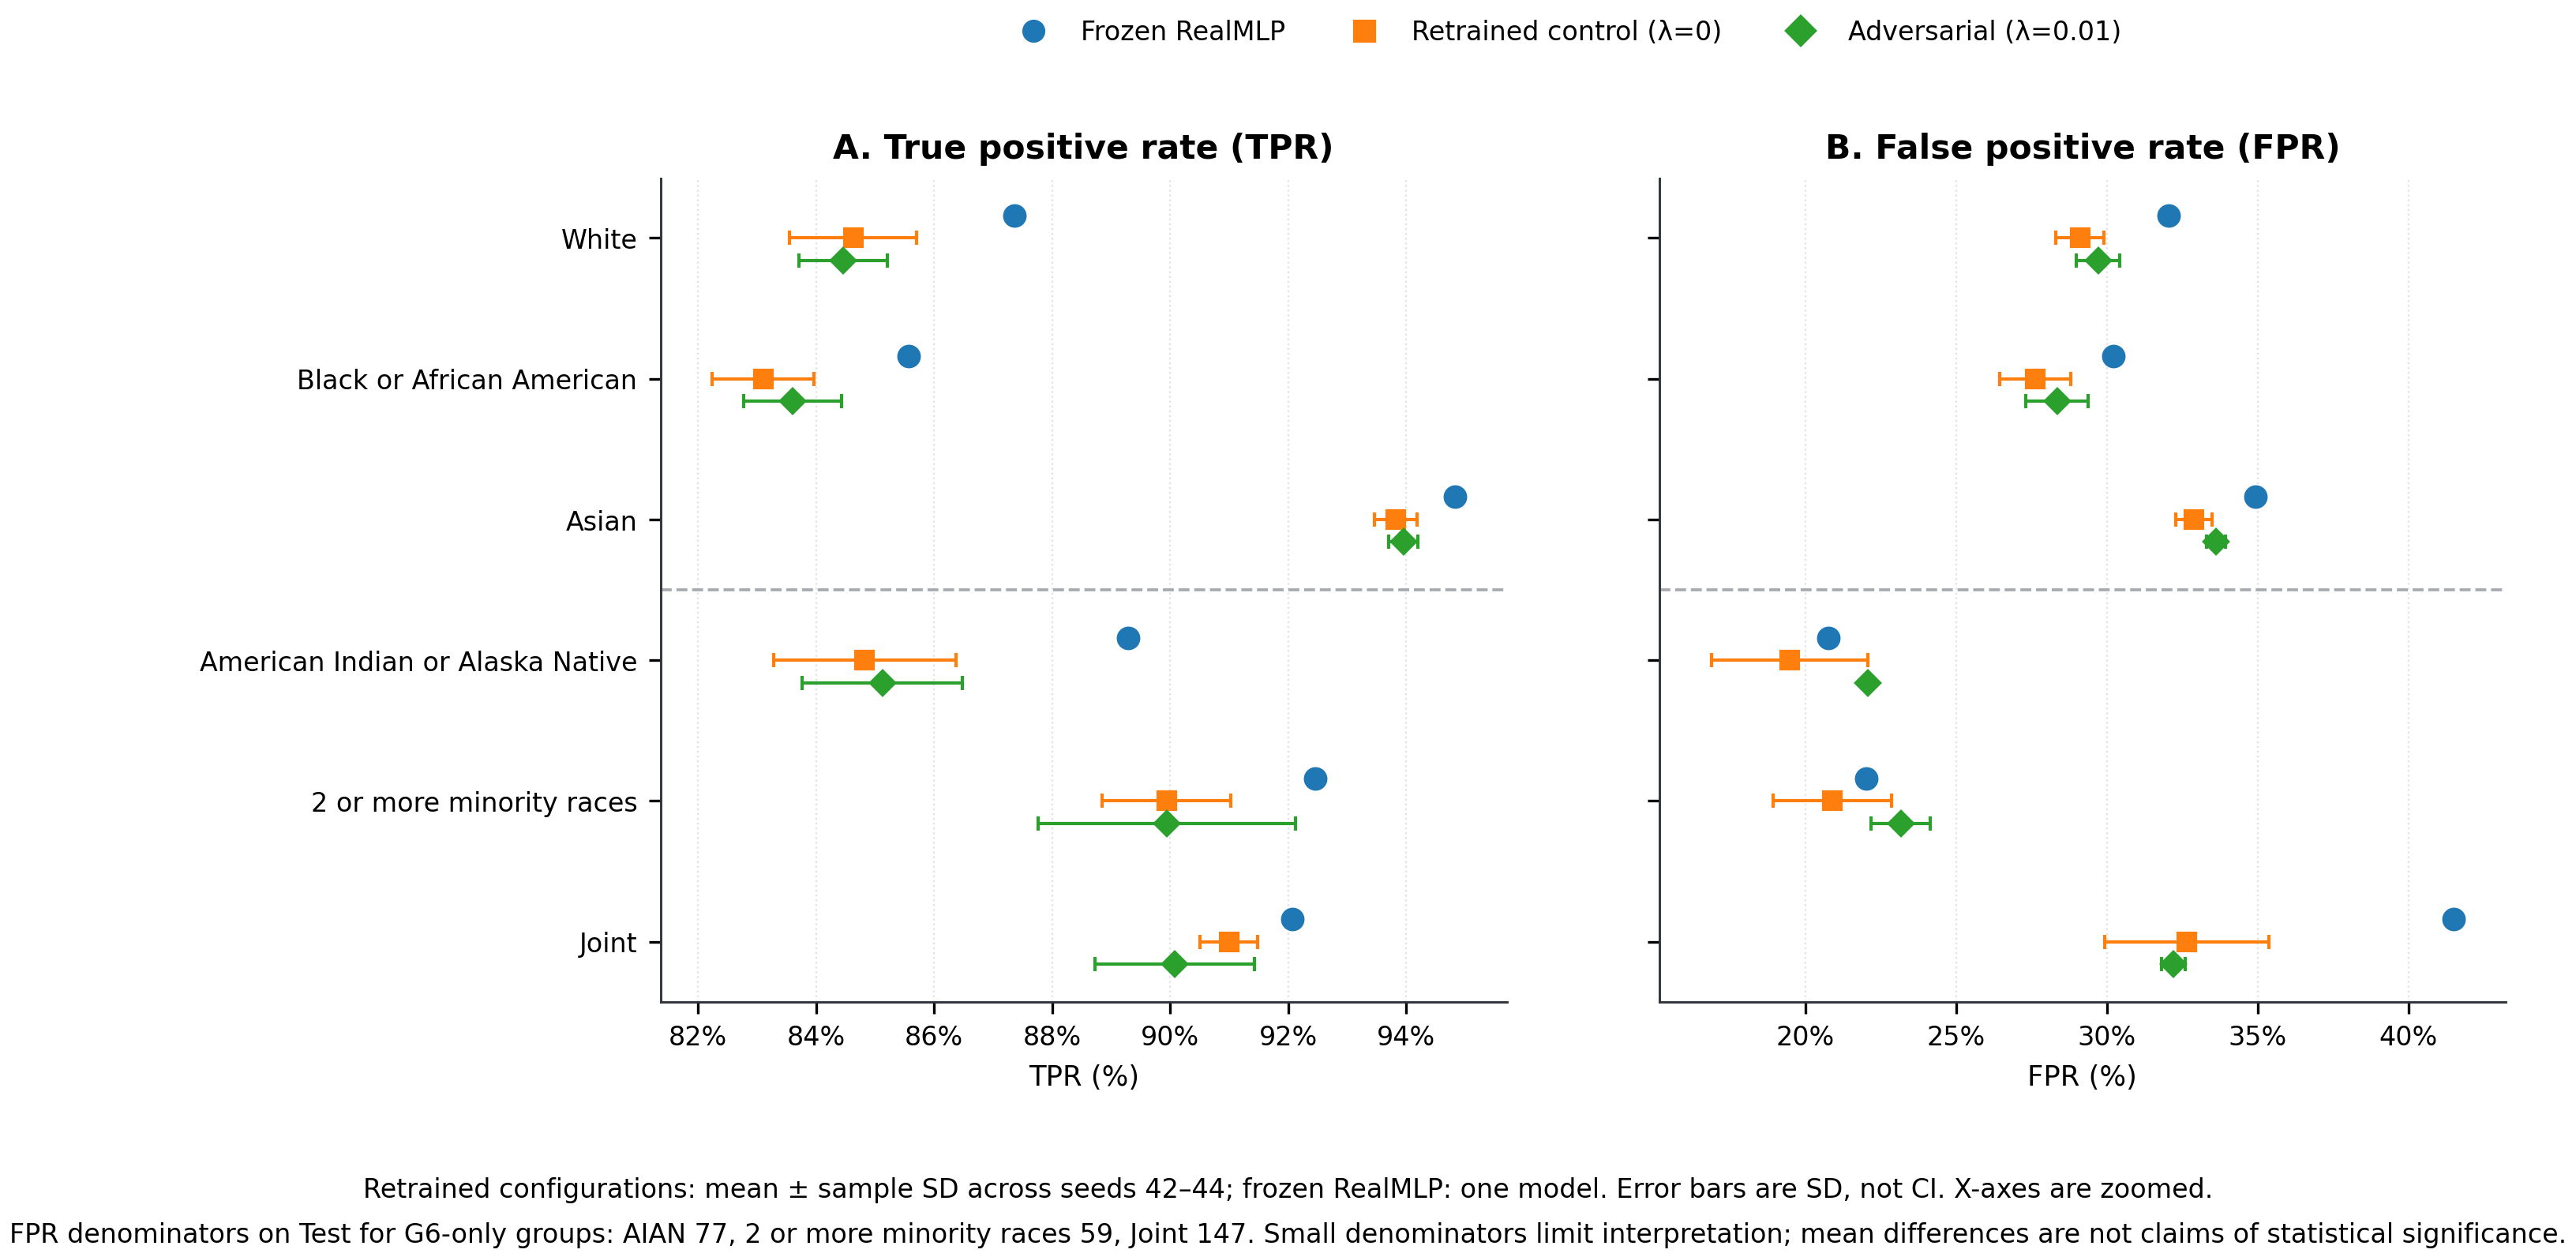

In [4]:
configuration_styles = {
    'frozen': {'label': 'Frozen RealMLP', 'color': '#1F77B4', 'marker': 'o', 'offset': 0.16},
    0.0: {'label': 'Retrained control (λ=0)', 'color': '#FF7F0E', 'marker': 's', 'offset': 0.0},
    0.01: {'label': 'Adversarial (λ=0.01)', 'color': '#2CA02C', 'marker': 'D', 'offset': -0.16},
}
fig, axes = plt.subplots(1, 2, figsize=(10.6, 5.7), sharey=True)
fig.subplots_adjust(left=0.25, right=0.985, top=0.82, bottom=0.21, wspace=0.18)
y = np.arange(len(g6_groups))[::-1]
metric_specs = [('tpr_approved', 'tpr_mean', 'tpr_sd', 'A. True positive rate (TPR)'), ('fpr_approved', 'fpr_mean', 'fpr_sd', 'B. False positive rate (FPR)')]
for ax, (frozen_metric, mean_column, sd_column, title) in zip(axes, metric_specs):
    frozen_values = frozen_realmlp.loc[g6_groups, frozen_metric].to_numpy(float) * 100
    frozen_style = configuration_styles['frozen']
    ax.scatter(frozen_values, y + frozen_style['offset'], color=frozen_style['color'], marker=frozen_style['marker'], s=38, zorder=3)
    all_values = [frozen_values]
    for adversary_lambda in [0.0, 0.01]:
        style = configuration_styles[adversary_lambda]
        summary = rq4b_group_summary[np.isclose(rq4b_group_summary['adversary_lambda'], adversary_lambda)].set_index('group').loc[g6_groups]
        means = summary[mean_column].to_numpy(float) * 100
        sample_sd = summary[sd_column].to_numpy(float) * 100
        ax.errorbar(means, y + style['offset'], xerr=sample_sd, fmt=style['marker'], linestyle='None', color=style['color'], ecolor=style['color'], elinewidth=1.0, capsize=2.2, markersize=5.2, zorder=2)
        all_values.extend([means - sample_sd, means + sample_sd])
    combined = np.concatenate(all_values)
    padding = max(0.8, 0.07 * np.ptp(combined))
    ax.set_xlim(combined.min() - padding, combined.max() + padding)
    ax.axhline(2.5, color='#A7ABB1', linestyle='--', linewidth=0.9)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel(f'{title.split("(")[1].rstrip(")")} (%)')
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(xmax=100, decimals=0))
    ax.set_yticks(y, g6_groups)
    polish(ax)
legend_handles = [mpl.lines.Line2D([], [], marker=style['marker'], linestyle='None', color=style['color'], markersize=6, label=style['label']) for style in configuration_styles.values()]
fig.legend(handles=legend_handles, loc='upper center', ncol=3, frameon=False, bbox_to_anchor=(0.61, 0.955))
small_denominator_note = f"FPR denominators on Test for G6-only groups: AIAN {frozen_fpr_denominators['American Indian or Alaska Native']}, 2 or more minority races {frozen_fpr_denominators['2 or more minority races']}, Joint {frozen_fpr_denominators['Joint']}."
fig.text(0.5, 0.065, 'Retrained configurations: mean ± sample SD across seeds 42–44; frozen RealMLP: one model. Error bars are SD, not CI. X-axes are zoomed.', ha='center', fontsize=8)
fig.text(0.5, 0.032, small_denominator_note + ' Small denominators limit interpretation; mean differences are not claims of statistical significance.', ha='center', fontsize=8)
fig03_paths = export_figure(fig, 'fig03_adversarial_group_error_rates')
display(Image(filename=str(fig03_paths[-1]), width=567))

## Checks and deliverable index

In [8]:
figure_paths = {
    'fig02_postprocessing_group_error_rates': fig02_paths,
    'fig03_adversarial_group_error_rates': fig03_paths,
    'fig04_postprocessing_target_eod_ba': fig04_paths,
    'fig05_adversarial_six_units': fig05_paths,
    'fig06_rq4b_secondary_deltas': fig06_paths,
}
for stem, paths in figure_paths.items():
    assert {path.suffix for path in paths} == {'.pdf', '.svg', '.png'}
    assert all(path.is_file() and path.stat().st_size > 0 for path in paths)
    png = mpl.image.imread(OUTPUT_ROOT / f'{stem}.png')
    assert png.shape[0] > 1000 and png.shape[1] > 1000

rq4b_inputs = [RQ4B_ROOT / 'run_manifest.json', RQ4B_STAGE / 'arm_metrics.csv', RQ4B_STAGE / 'group_metrics.csv', RQ4B_STAGE / 'matched_deltas.csv', RQ4B_STAGE / 'bootstrap_summary.csv', RQ4B_STAGE / 'receipt.json', RQ4B_PACKAGE / 'receipt.json']
source_manifest = {
    'schema_version': 'paper_figures_source_manifest_v3',
    'notebook': 'notebooks/dataset_b/14_research_report.ipynb',
    'figures': {
        'fig02_postprocessing_group_error_rates': {'status': 'READY_RENDERED', 'partition': 'test', 'scope': 'G3', 'models': ['xgboost', 'realmlp'], 'metrics': ['tpr', 'fpr'], 'comparison': 'frozen baseline versus G3 ThresholdOptimizer', 'decision_seed': 42, 'interval_provenance': 'none; deterministic seed-42 before/after rates only', 'axes': 'zoomed and not zero-based', 'inputs': [{'path': RQ4A_G3_GROUP_METRICS.relative_to(REPO_ROOT).as_posix(), 'sha256': sha256(RQ4A_G3_GROUP_METRICS), 'run_id': 'rq4a3_postproc_20261017_01'}]},
        'fig03_adversarial_group_error_rates': {'status': 'READY_RENDERED', 'partition': 'test', 'scope': 'G6 with dashed G3 boundary', 'model': 'realmlp', 'metrics': ['tpr_approved', 'fpr_approved'], 'comparison': ['frozen RealMLP', 'retrained lambda=0', 'adversarial lambda=0.01'], 'seed_policy': [42, 43, 44], 'interval_provenance': 'sample SD across seeds 42/43/44 with ddof=1; not CI or sampling uncertainty', 'axes': 'zoomed and not zero-based', 'small_fpr_denominators': frozen_fpr_denominators.loc[['American Indian or Alaska Native', '2 or more minority races', 'Joint']].to_dict(), 'inputs': [{'path': (RQ3_ROOT / 'group_metrics.csv').relative_to(REPO_ROOT).as_posix(), 'sha256': sha256(RQ3_ROOT / 'group_metrics.csv'), 'run_id': 'rq3_fairness_20261010_01'}, {'path': (RQ4B_STAGE / 'group_metrics.csv').relative_to(REPO_ROOT).as_posix(), 'sha256': sha256(RQ4B_STAGE / 'group_metrics.csv'), 'run_id': 'rq4b3_test_20261024_01'}]},
        'fig04_postprocessing_target_eod_ba': {'status': 'READY_RENDERED', 'partition': 'test', 'rows': rq4a_order, 'ci_provenance': 'accepted postprocessor-refit paired Test bootstrap 95% CI', 'inputs': [{'path': (root / 'reporting/model_summary.json').relative_to(REPO_ROOT).as_posix(), 'sha256': sha256(root / 'reporting/model_summary.json'), 'run_id': json.loads((root / 'reporting/model_summary.json').read_text())['run_id']} for root in RQ4A_ROOTS.values()]},
        'fig05_adversarial_six_units': {'status': 'READY_RENDERED', 'partition': 'test', 'units': rq4b_units['label'].tolist(), 'metrics': ['eod3', 'balanced_accuracy'], 'inputs': [{'path': path.relative_to(REPO_ROOT).as_posix(), 'sha256': sha256(path), 'run_id': 'rq4b3_test_20261024_01'} for path in rq4b_inputs]},
        'fig06_rq4b_secondary_deltas': {'status': 'READY_RENDERED_WITH_DISCLOSED_DPD_CI_OMISSION', 'partition': 'test', 'comparator': 'same-seed lambda=0', 'metrics': ['delta_eod6', 'delta_dpd3', 'delta_dpd6'], 'transform': 'DPD = max(group predicted-approved rate) - min(group predicted-approved rate); delta = lambda0.01 - same-seed lambda0', 'ci_provenance': {'delta_eod6': 'stored paired Test bootstrap 95% CI', 'delta_dpd3': 'unavailable; point only', 'delta_dpd6': 'unavailable; point only'}, 'inputs': [{'path': path.relative_to(REPO_ROOT).as_posix(), 'sha256': sha256(path), 'run_id': 'rq4b3_test_20261024_01'} for path in rq4b_inputs]},
    },
}
figure_index = {
    'figure_1': {'status': 'UNCHANGED_OUTSIDE_NOTEBOOK'},
    'figures': {stem: {'files': [path.relative_to(REPO_ROOT).as_posix() for path in paths], 'formats': ['PDF', 'SVG', 'PNG'], 'png_dpi': 300, 'internal_title': False, 'panel_labels': 'figure_specific', 'marker': 'figure_specific', 'qa_status': 'PENDING_EXTERNAL_VISUAL_INSPECTION'} for stem, paths in figure_paths.items()},
    'omissions': {'fig02_postprocessing_group_error_rates': 'No seed-variability interval; primary deterministic decision seed 42 only.', 'fig03_adversarial_group_error_rates': 'Frozen RealMLP is one model without an error bar; retrained error bars are sample SD, not CI.', 'fig06_rq4b_secondary_deltas': 'No authoritative paired DPD3/DPD6 bootstrap CI; DPD deltas are point only.'},
}
(OUTPUT_ROOT / 'source_manifest.json').write_text(json.dumps(source_manifest, indent=2, ensure_ascii=False), encoding='utf-8')
(OUTPUT_ROOT / 'figure_index.json').write_text(json.dumps(figure_index, indent=2, ensure_ascii=False), encoding='utf-8')
notes = f"""# Verification notes

- Rendered stems: {', '.join(figure_paths)}.
- Formats: PDF, SVG, PNG at 300 DPI.
- Internal titles and panel labels: none.
- Figure 2 markers: circle before, square after; connectors are within group only.
- Figure 3 markers: circle frozen, square retrained control, diamond adversarial; no lines join groups.
- Figure 2 has no seed-variability interval; Figure 3 error bars are sample SD across seeds 42--44 with ddof=1, not confidence intervals.
- RQ4b Figure 5 is restricted to seeds 42/43/44 and lambda 0/0.01.
- Figure 6 contains matched delta EOD6, DPD3, and DPD6; DPD deltas have no inferred CI.
- Frozen artifacts were read only; no fit, inference, threshold selection, Test re-evaluation, or bootstrap generation occurred.
- Rerender manually from the notebook; this notebook is not auto-executed by the implementation task.
"""
(OUTPUT_ROOT / 'verification_notes.md').write_text(notes, encoding='utf-8')
print('Export validation: PASS')
for stem, paths in figure_paths.items():
    png = OUTPUT_ROOT / f'{stem}.png'
    image = mpl.image.imread(png)
    print(stem, 'pixels=', image.shape[1], 'x', image.shape[0], 'files=', [path.name for path in paths])

Export validation: PASS
fig02_postprocessing_group_error_rates pixels= 3036 x 1660 files= ['fig02_postprocessing_group_error_rates.pdf', 'fig02_postprocessing_group_error_rates.svg', 'fig02_postprocessing_group_error_rates.png']
fig03_adversarial_group_error_rates pixels= 3263 x 1592 files= ['fig03_adversarial_group_error_rates.pdf', 'fig03_adversarial_group_error_rates.svg', 'fig03_adversarial_group_error_rates.png']
fig04_postprocessing_target_eod_ba pixels= 1416 x 1408 files= ['fig04_postprocessing_target_eod_ba.pdf', 'fig04_postprocessing_target_eod_ba.svg', 'fig04_postprocessing_target_eod_ba.png']
fig05_adversarial_six_units pixels= 1416 x 1558 files= ['fig05_adversarial_six_units.pdf', 'fig05_adversarial_six_units.svg', 'fig05_adversarial_six_units.png']
fig06_rq4b_secondary_deltas pixels= 1416 x 1828 files= ['fig06_rq4b_secondary_deltas.pdf', 'fig06_rq4b_secondary_deltas.svg', 'fig06_rq4b_secondary_deltas.png']
